In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

import astropy.table as at
from astropy.table import Table
import astropy.units as u
import scipy

from cats.pawprint.pawprint import Pawprint
from cats.CMD import Isochrone
from cats.inputs import stream_inputs as inputs
from cats.proper_motions import ProperMotionSelection, rough_pm_poly
import cats.photometry as phot
from cats.data import make_astro_photo_joined_data

import galstreams as gst
from pyia import GaiaData
import gala.coordinates as gc

In [2]:
data = Table.read("/Users/Tavangar/Work/gd1-dr3/data/GD1-region-alldata.fits")

In [3]:
mws = gst.MWStreams(verbose=False, implement_Off=True)

name = 'GD-1'
ms_name = 'GD-1-PB18'
g = GaiaData(f'/Users/Tavangar/Work/CATS_Workshop/data/GaiaDR3-{name}-all.fits')
p = phot.PS1Phot(f'/Users/Tavangar/Work/CATS_Workshop/data/PS1DR2-{name}_xm.fits')
gs = mws[ms_name]

Initializing galstreams library from master_log... 


In [4]:
stream_fr = gs.stream_frame

track = gs.track.transform_to(stream_fr)
if np.all(track.distance.value == 0):
    raise ValueError(
        "A distance track is required: this stream has no distance information in "
        "the galstreams track."
    )

# interpolator to get predicted distance from phi1
dist_interp = scipy.interpolate.InterpolatedUnivariateSpline(
    track.phi1.degree, track.distance.value, k=1
)

# get stream coordinates for all stars, and reflex correct with predicted distance
_c_tmp = g.get_skycoord(distance=False).transform_to(stream_fr)
c = g.get_skycoord(
    distance=dist_interp(_c_tmp.phi1.degree) * track.distance.unit,
    radial_velocity=0 * u.km / u.s,
)
c_stream = c.transform_to(stream_fr)
c_stream_refl = gc.reflex_correct(c_stream)

# start building the final joined table
gaia_data = g.data.copy()
for name in ["phi1", "phi2", "pm_phi1_cosphi2", "pm_phi2"]:
    gaia_data[name] = getattr(c_stream_refl, name)
    if name not in ["phi1", "phi2"]:
        gaia_data[f"{name}_unrefl"] = getattr(c_stream, name)

In [5]:
joined = at.join(gaia_data, p.data, keys="source_id")

In [6]:
joined.write("/Users/Tavangar/Work/gd1-dr3/data/GD-1_all_data_2026.fits")

OSError: File /Users/Tavangar/Work/gd1-dr3/data/GD-1_all_data_2026.fits already exists. If you mean to replace it then use the argument "overwrite=True".

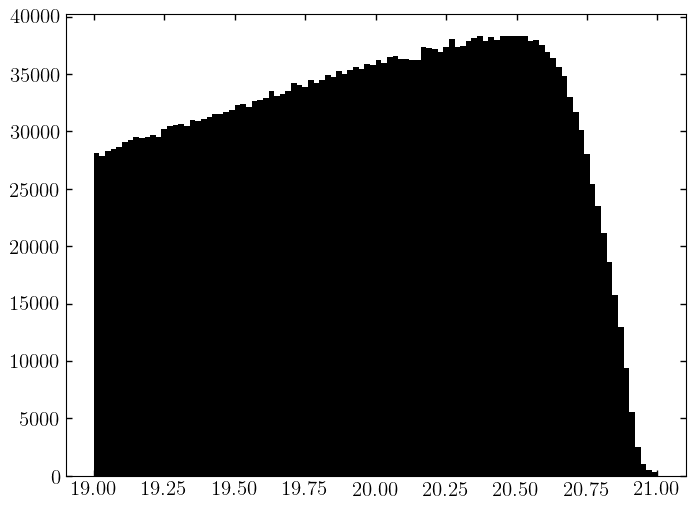

In [7]:
plt.hist(joined['phot_g_mean_mag'], bins=100, range=[19,21])
plt.show()

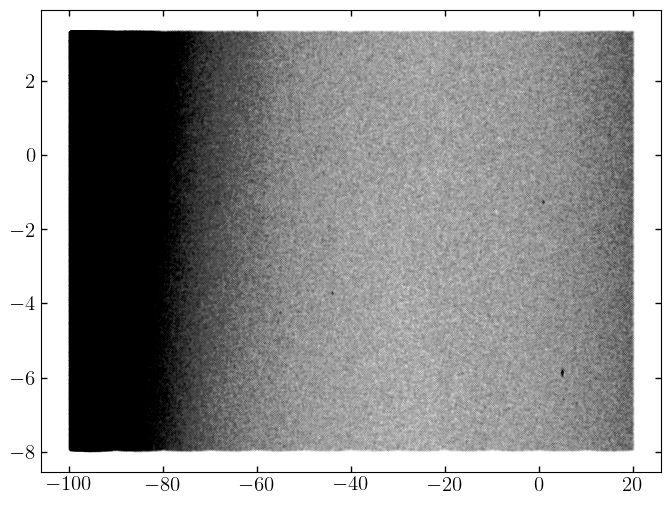

In [8]:
plt.scatter(joined['phi1'], joined['phi2'], s=0.0001)
plt.show()

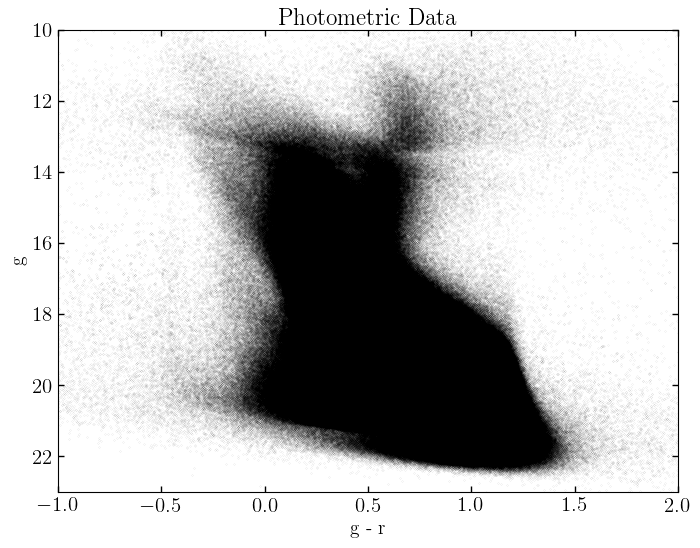

In [9]:
plt.scatter(joined['g0'] - joined['r0'], joined['g0'], s=0.001)
plt.xlabel('g - r')
plt.ylabel('g')
plt.title('Photometric Data')
plt.xlim(-1, 2); plt.ylim(23, 10)
plt.show()

In [10]:
phi1_lim = (-100, 20)

on_stream_outline = Pawprint.pawprint_from_galstreams(
        stream_name = "GD-1",
        pawprint_ID = "pricewhelan2018",
        width=2.0 * u.deg,
        phi1_lim=phi1_lim)

on_stream_patch = mpl.patches.Polygon(
    on_stream_outline.skyprint["stream"].vertices[::50],
)

on_points = np.vstack((joined['phi1'], joined['phi2'])).T
on_mask = on_stream_patch.get_path().contains_points(on_points)
off_mask = ~on_mask

_, pm_mask = rough_pm_poly(on_stream_outline, joined, buffer=2)
bkg_tbl = joined[pm_mask & off_mask]

Modifying/extrapolating galstreams track
Modifying/extrapolating galstreams track


In [ ]:
run_data_ = joined[pm_mask]
bkg_data_ = joined[pm_mask & off_mask]
# stream_data_ = joined[pmsel.pm12_mask & (iso_mask | hb_mask) & on_mask]

NameError: name 'pmsel' is not defined

In [48]:
bkg_data_[(bkg_data_['phot_g_mean_mag']<20.5) & (bkg_data_['g0']<22) & (bkg_data_['r0']<22) & \
          (bkg_data_['g0']>0) & (bkg_data_['r0']>0)]

source_id,ra,dec,parallax,parallax_error,pmra,pmra_error,pmdec,pmdec_error,ra_parallax_corr,ra_pmra_corr,ra_pmdec_corr,dec_parallax_corr,dec_pmra_corr,dec_pmdec_corr,parallax_pmra_corr,parallax_pmdec_corr,pmra_pmdec_corr,phot_g_mean_mag,phot_g_mean_flux_over_error,phot_bp_mean_mag,phot_bp_mean_flux_over_error,phot_rp_mean_mag,phot_rp_mean_flux_over_error,ruwe,astrometric_matched_transits,phi1,phi2,pm_phi1_cosphi2,pm_phi1_cosphi2_unrefl,pm_phi2,pm_phi2_unrefl,objID,raMean,decMean,nDetections,ng,nr,ni,nz,ny,gMeanPSFMag,rMeanPSFMag,iMeanPSFMag,zMeanPSFMag,yMeanPSFMag,gMeanPSFMagErr,rMeanPSFMagErr,iMeanPSFMagErr,zMeanPSFMagErr,yMeanPSFMagErr,g0,r0,i0,z0,y0
,,,,,,,,,,,,,,,,,,,,,,,,,,deg,deg,mas / yr,mas / yr,mas / yr,mas / yr,,,,,,,,,,,,,,,,,,,,,,,,
int64,float64,float64,float64,float32,float64,float32,float64,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,int16,float64,float64,float64,float64,float64,float64,int64,float64,float64,int16,int16,int16,int16,int16,int16,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64
576748068435698048,134.13841688083966,0.744322167695016,0.2984067087733031,0.0703053,-3.8139182053063028,0.06819834,-4.5132924531099246,0.047343124,0.056212936,-0.09234336,-0.020601856,0.16351864,0.03781591,-0.2740701,0.32953483,-0.2281111,-0.08119383,16.797646,1971.64,17.151026,164.42722,16.287083,325.6407,0.970057,53,-77.47744548442915,-7.900720693451336,-0.32711280650848434,-5.8186532841010195,4.091166779894412,1.0291038837193527,108891341384293660,134.13842013446921,0.744326734500542,74,12,13,23,13,13,17.189899444580078,16.777700424194336,16.619600296020508,16.57939910888672,16.52669906616211,0.003019999945536256,0.0046430001966655254,0.0030249999836087227,0.0026889999862760305,0.007087999954819679,17.03443819284439,16.666397623717785,16.53716466575861,16.51460725069046,16.473424673080444
576748244530543488,134.16732705372561,0.7688112975036265,0.9022941098563593,0.12843332,-0.40705646569708565,0.12549128,-5.993332435999002,0.09447704,0.10845018,-0.046182457,0.07873066,0.022839377,0.057953816,-0.32184994,0.3101018,-0.082185306,-0.13549173,17.862417,983.333,18.390556,70.363174,17.150635,113.5506,1.0864235,54,-77.44140251916025,-7.9134037267407695,0.10736800456245668,-5.385816712103616,0.3998047000624386,-2.6605839581356805,108921341673483087,134.16732781798333,0.7688165810429347,54,6,10,12,15,11,18.55579948425293,17.82939910888672,17.48699951171875,17.343900680541992,17.237600326538086,0.005909999832510948,0.005291000008583069,0.00647500017657876,0.0067900000140070915,0.01056700013577938,18.396631002426147,17.71544210612774,17.402598060667515,17.277563750743866,17.183055512607098
576750301818727936,134.22981963824748,0.8305934323875556,0.4623623504038562,0.45960036,-2.7148906452442993,0.44875842,-8.888072858020927,0.3240633,0.0007706698,-0.11292817,-0.07473175,-6.6603854e-05,-0.0378848,-0.19379774,0.32304,-0.05691278,-0.16431886,19.66402,341.23932,20.072033,19.38162,19.151209,24.04379,1.0598296,52,-77.35576351809101,-7.936359590433996,-3.5507685107746574,-9.0478473982254,0.9346461739946219,-2.122481520190257,108991342298407106,134.22982148012173,0.8305976504047762,60,8,11,16,14,11,20.13800048828125,19.618799209594727,19.464599609375,19.364299774169922,19.37420082092285,0.027828000485897064,0.013590999878942966,0.006852999795228243,0.03171699866652489,0.030220000073313713,19.984066665172577,19.50858996808529,19.38297390937805,19.300144501030445,19.321449849754572
576760064280542592,134.14547166643905,0.7975047222182825,0.2592137893508311,0.08831908,1.2105295907878606,0.0872203,-7.551246770848138,0.06547589,0.13469785,-0.11898727,0.061640035,0.05596912,0.057629358,-0.37289673,0.27530864,-0.11406384,-0.098390386,17.17117,1437.0532,17.464699,136.93924,16.720589,161.62434,1.0645345,47,-77.42744966143749,-7.880088957809821,-0.42560899496508425,-5.919429382531986,-1.77

In [54]:
from ugali.analysis.isochrone import factory as isochrone_factory

In [58]:
Y_p = 0.245  # Primordial He abundance (WMAP, 2003)
c = 1.54  # He enrichment ratio
ZX_solar = 0.0229
z = (1 - Y_p) / ((1 + c) + (1 / ZX_solar) * 10 ** (2.5))

iso = isochrone_factory(
        "Dotter",
        survey='PS1',
        age=12,
        distance_modulus=14.5,
        z=z,
        band_1='g',
        band_2='r',
    )

In [61]:
iso.mass_init

array([0.1062848 , 0.11723399, 0.11731095, 0.11876461, 0.12260235,
       0.12891288, 0.13155189, 0.1316364 , 0.13774166, 0.14061282,
       0.14457951, 0.15471154, 0.1572363 , 0.15768062, 0.16449258,
       0.18048863, 0.18368294, 0.19819431, 0.19833722, 0.206538  ,
       0.21786586, 0.23370691, 0.2368396 , 0.24241038, 0.25806368,
       0.25852947, 0.2657156 , 0.27209428, 0.27947343, 0.28670254,
       0.28684138, 0.29798729, 0.30416545, 0.30423298, 0.30832717,
       0.31475409, 0.32072399, 0.32079816, 0.33095009, 0.33202261,
       0.33294269, 0.33306623, 0.33751218, 0.33898016, 0.34267672,
       0.34358112, 0.34448276, 0.346124  , 0.34986827, 0.35338334,
       0.35389187, 0.35638731, 0.35787523, 0.36017555, 0.3616748 ,
       0.362268  , 0.36872065, 0.37515384, 0.37526196, 0.3771917 ,
       0.38380997, 0.38888903, 0.39558252, 0.40756357, 0.41545355,
       0.42161154, 0.42182694, 0.43311907, 0.4486134 , 0.45041369,
       0.4513377 , 0.46876816, 0.47160965, 0.47237224, 0.48296

In [11]:
stream_name = 'GD-1'
phi1_lim = (-100, 20)
pawprint = Pawprint.pawprint_from_galstreams(inputs[stream_name]['short_name'],
                                                 inputs[stream_name]['pawprint_id'],
                                                 width=inputs[stream_name]['width'] * u.deg,
                                                 phi1_lim=phi1_lim)

Modifying/extrapolating galstreams track
Modifying/extrapolating galstreams track


In [22]:
 # rough pm cut to start with (this comes only from the galstreams proper motion tracks)
pawprint.pmprint, pm_mask = rough_pm_poly(pawprint, joined, buffer=2)

In [23]:
# Create the CMD cuts
iso_obj_ = Isochrone(data, inputs[stream_name], pawprint=pawprint)
_, _, _, _, pprint = iso_obj_.simpleSln(mass_thresh=0.83)

/Users/Tavangar/Work/CATS_Workshop/cats/cats/CMD.py:294: RuntimeWarning: invalid value encountered in divide
  signal = signal / signal_counts


-40.18182129005669
Fitting for peak pm location
Pre-fitting mean PM values: -13.031, -3.108
Post-fitting (pm1_mean, pm2_mean, pm1_std, pm2_std): [np.float64(-13.280976914806441), np.float64(-3.1840547669289494), np.float64(0.4001460380309086), np.float64(0.5297003277006049)] 

Producing the polygon and mask


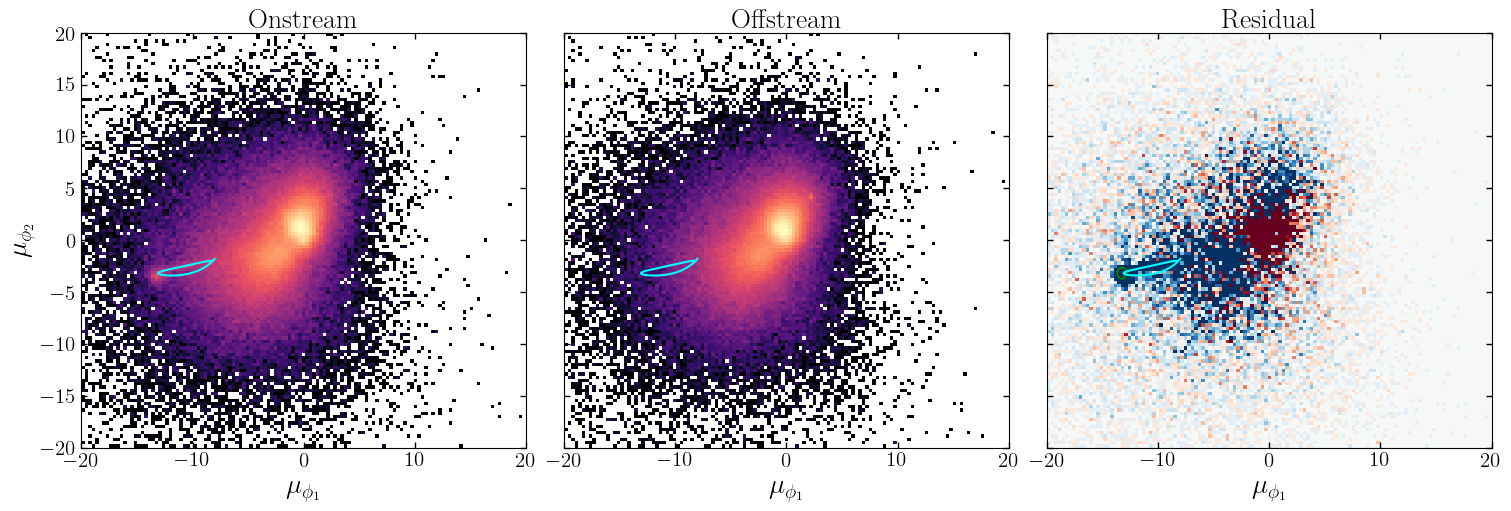

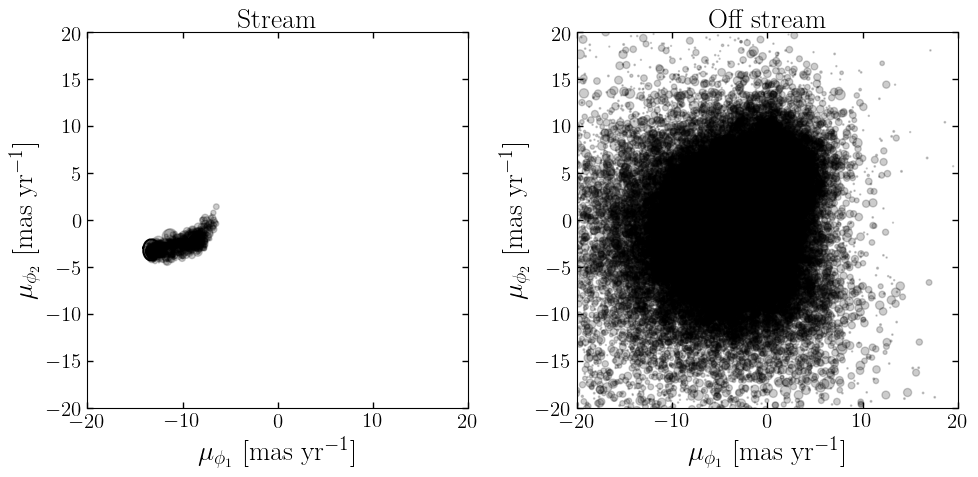

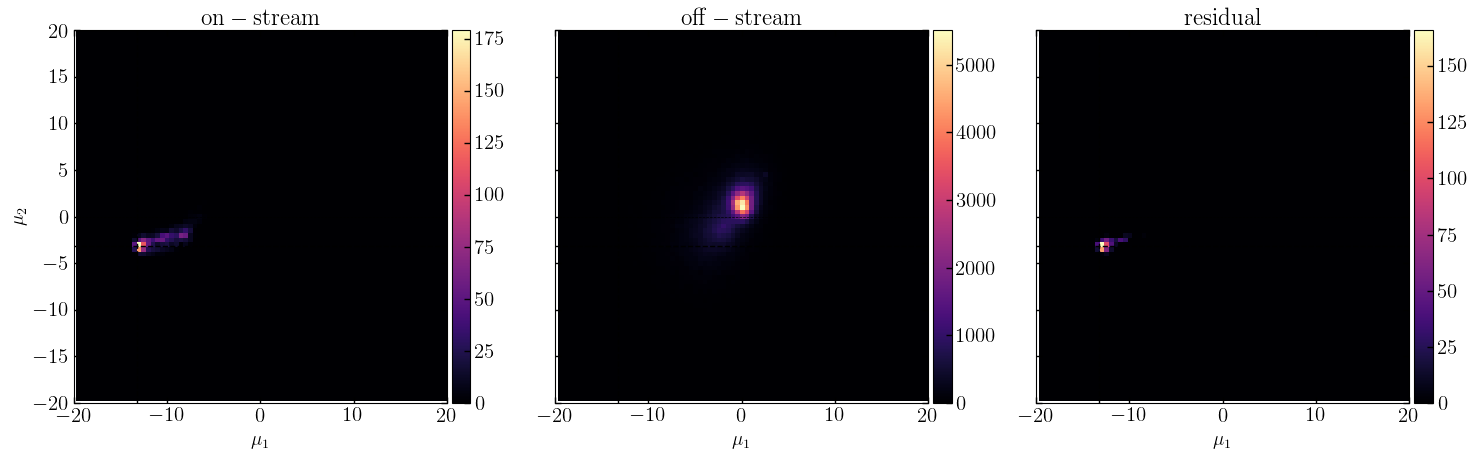

In [27]:
pmsel = ProperMotionSelection(joined, inputs[stream_name], pprint,
                                n_dispersion_phi1=3, n_dispersion_phi2=3, cutoff=0.1, plot=True)

iso_obj = Isochrone(joined, inputs[stream_name], pawprint=pmsel.pawprint,)
_, iso_mask, _, hb_mask, pprint = iso_obj.simpleSln(mass_thresh=0.83)

In [28]:
##### rough pm cut to start with (this comes only from the galstreams proper motion tracks)
pawprint.pmprint, pm_mask = rough_pm_poly(pawprint, joined, buffer=2)

In [30]:
run_data_ = iso_obj.cat[pm_mask]# & (iso_mask | hb_mask)]
bkg_data_ = iso_obj.cat[pm_mask & ~iso_obj.on_skymask]
stream_data_ = iso_obj.cat[pmsel.pm12_mask & (iso_mask | hb_mask) & iso_obj.on_skymask]

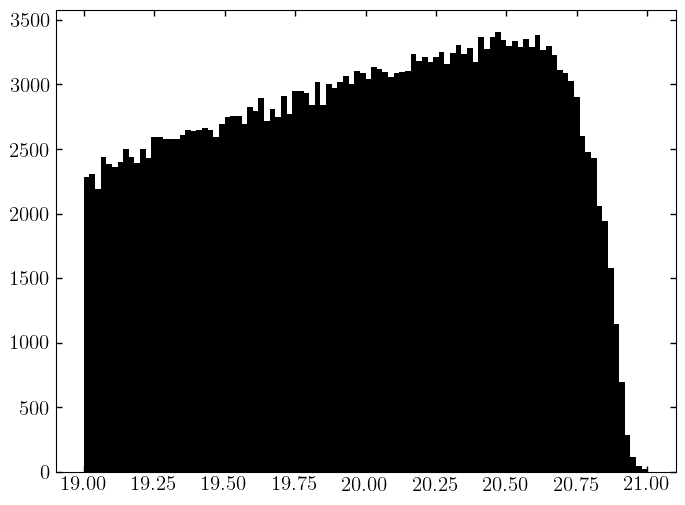

In [37]:
plt.hist(run_data_['phot_g_mean_mag'], bins=100, range=[19,21])
plt.show()

In [33]:
print(len(run_data_))
print(len(bkg_data_))

542836
444699


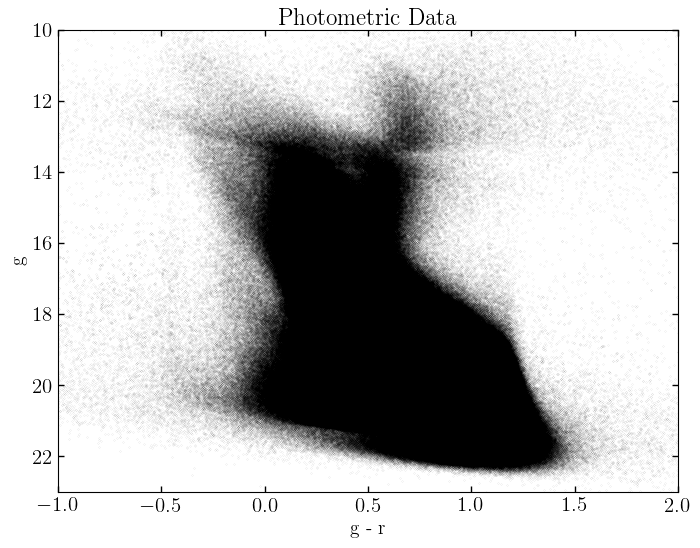

In [36]:
plt.scatter(joined['g0'] - joined['r0'], joined['g0'], s=0.001)
plt.xlabel('g - r')
plt.ylabel('g')
plt.title('Photometric Data')
plt.xlim(-1, 2); plt.ylim(23, 10)
plt.show()

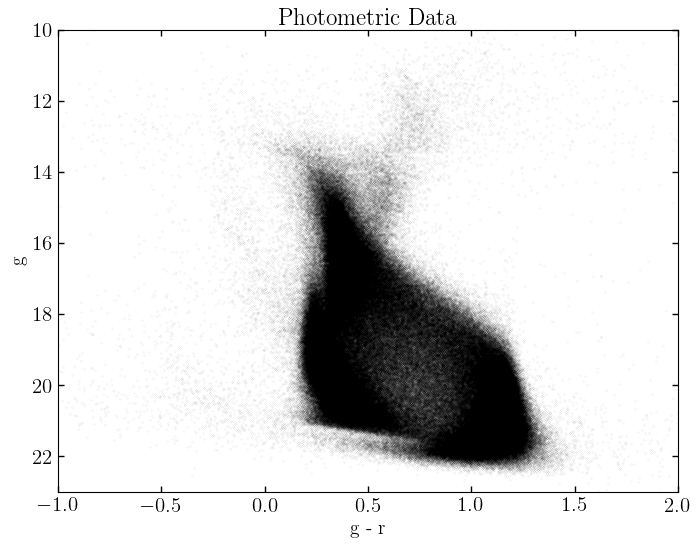

In [38]:
plt.scatter(run_data_['g0'] - run_data_['r0'], run_data_['g0'], s=0.001)
plt.xlabel('g - r')
plt.ylabel('g')
plt.title('Photometric Data')
plt.xlim(-1, 2); plt.ylim(23, 10)
plt.show()

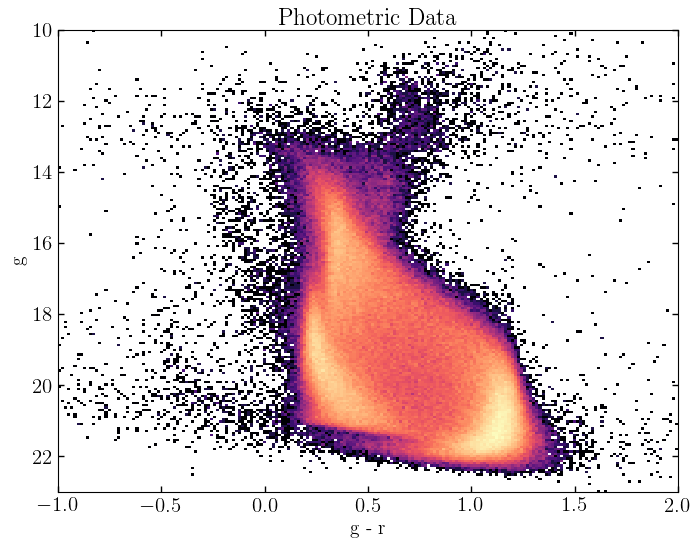

In [35]:
import matplotlib as mpl
plt.hist2d(bkg_data_['g0'] - bkg_data_['r0'], bkg_data_['g0'], bins=200, range=[[-1, 2], [10, 23]], norm=mpl.colors.LogNorm())
plt.xlabel('g - r')
plt.ylabel('g')
plt.title('Photometric Data')
plt.gca().invert_yaxis()
plt.show()

In [39]:
import pickle
post_cats = {'run_data': run_data_,
         'bkg_data': bkg_data_,
         'stream_data': stream_data_,
         'pawprint': pawprint,
         'iso_obj': iso_obj}
with open('../../data/post_cats_data_flow_version.pkl', 'wb') as param_file:
    pickle.dump(post_cats, param_file)

